# Small-Cap Buyout Fund-of-Funds — Portfolio Performance Analysis

**A walkthrough of how a fund-of-funds analyst evaluates a portfolio of primary fund commitments, co-investments, and secondaries — written for an investment committee audience.**

> **Disclaimer:** every fund, cash flow, NAV, index level, and manager profile in this notebook is **synthetically generated** (seeded and reproducible via `pe_analytics.cash_flows`, `pme_benchmarking`, and `manager_scorecard`). None of it represents a real fund, GP, or investment. The methodology — how IRR, MOIC, DPI, RVPI, TVPI, and PME are computed, and how a pacing model and a manager scorecard are built — is real and industry-standard; the data behind it is illustrative only.

## What this notebook covers

1. **The portfolio** — 10 positions across primaries, co-investments, and a secondary, spanning 2013–2020 vintages
2. **Core performance metrics** — IRR (XIRR on dated cash flows), MOIC, DPI, RVPI, TVPI, per fund and portfolio-wide
3. **Public Market Equivalent (PME) benchmarking** — Kaplan-Schoar and Long-Nickels PME vs. a synthetic Russell 2000-like index
4. **The J-curve** — cumulative net cash flow shape, single fund and portfolio-averaged
5. **Commitment pacing** — projecting a fund-of-funds' aggregate liquidity position under a steady annual commitment plan
6. **Manager due-diligence scorecard** — a structured qualitative framework alongside the quantitative numbers
7. **Investment committee summary**

In [1]:
from datetime import date

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

from pe_analytics.cash_flows import generate_fund_portfolio
from pe_analytics.irr_moic import fund_metrics, portfolio_metrics
from pe_analytics.pme_benchmarking import (
    generate_synthetic_index,
    pme_analysis,
    portfolio_kaplan_schoar_pme,
)
from pe_analytics.jcurve import single_fund_jcurve, portfolio_average_jcurve
from pe_analytics.pacing_model import project_commitment_pacing, PacingAssumptions
from pe_analytics.manager_scorecard import generate_synthetic_manager_profiles, score_manager

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

AS_OF_DATE = date(2026, 6, 30)

# --- validated categorical palette (see dataviz skill / references/palette.md) ---
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948",
)
STATUS_GOOD, STATUS_CRITICAL = "#0ca30c", "#d03b3b"
INK, INK_SECONDARY, INK_MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"

STRATEGY_COLOR = {"primary": BLUE, "co-investment": ORANGE, "secondary": AQUA}

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": BASELINE,
    "axes.labelcolor": INK_SECONDARY,
    "axes.titlecolor": INK,
    "text.color": INK,
    "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED,
    "grid.color": GRID,
    "font.size": 10.5,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

## 1. The Portfolio

We generate a synthetic **10-position small-cap buyout fund-of-funds portfolio**, spanning **2013–2020 vintage years**, deployed across the three access points 747 Capital and similar FoF platforms actually use:

- **Primary fund commitments** (7 positions) — diversified, blind-pool commitments to a GP's fund, called down over ~5 years and harvested over the following 5-7
- **Co-investments** (2 positions) — direct, single-deal exposure alongside a GP, typically called almost entirely up front with a single (or near-single) exit event — higher dispersion, faster J-curve
- **A secondary interest** (1 position) — an LP interest purchased several years into an existing fund's life, priced off NAV at a discount, which mutes the early J-curve since capital is deployed against an already partly-realized portfolio

This mix is deliberate: a FoF doesn't just pick funds, it blends **strategies with different cash flow shapes and risk/return profiles** to manage the timing and magnitude of its own liquidity needs — which is exactly what Section 5 (pacing) comes back to.

In [2]:
funds = generate_fund_portfolio(as_of_date=AS_OF_DATE)

portfolio_summary = pd.DataFrame([
    {
        "Fund ID": f.fund_id,
        "Name": f.name,
        "Strategy": f.strategy,
        "Vintage": f.vintage_year,
        "Sector Focus": f.sector_focus,
        "Commitment ($)": f.commitment,
        "Fund Life (yrs)": round(f.fund_life_years, 1),
    }
    for f in funds
]).sort_values("Vintage").reset_index(drop=True)

print(f"Total committed capital: ${portfolio_summary['Commitment ($)'].sum():,.0f} across {len(funds)} positions")
portfolio_summary

Total committed capital: $99,198,103 across 10 positions


,Fund ID,Name,Strategy,Vintage,Sector Focus,Commitment ($),Fund Life (yrs)
0,F01,Meridian Capital Partners II,primary,2013,Industrials & Manufacturing,"11,044,558.81",11.40
1,F02,Cascade Buyout Fund III,primary,2014,Business Services,"8,907,637.40",11.00
2,F03,Stonebridge Equity Partners IV,primary,2015,Healthcare Services,"9,746,869.56",9.60
3,F04,Project Delta Co-Invest,co-investment,2015,Consumer & Retail,"8,350,599.68",4.70
4,F05,Ironwood Partners II,primary,2016,Tech-Enabled Services,"11,115,003.62",11.20
5,F06,Summit Ridge Capital III,primary,2017,Niche Industrials,"10,363,661.97",9.10
6,F07,Harborview Equity Partners IV,primary,2018,Specialty Distribution,"11,664,047.38",9.70
7,F08,Redwood Private Equity III (Secondary Interest),secondary,2018,Education Services,"8,377,866.67",11.20
8,F09,Pinnacle Growth Partners II,primary,2019,Food & Beverage,"9,203,794.77",10.50
9,F10,Project Beacon Co-Invest,co-investment,2020,Building Products,"10,424,063.28",3.90


**Strategy mix:** 7 primaries, 2 co-investments, 1 secondary — a primary-led portfolio (the core of most FoF programs) with a modest opportunistic sleeve, which is a realistic allocation for a small-cap buyout FoF layering in co-investment and secondary exposure to enhance returns and manage the J-curve, without making them the core strategy.

## 2. Core Performance Metrics

Before looking at a single number, it's worth being precise about what each one actually measures — because a fund-of-funds analyst tracks **all four** (IRR, MOIC/TVPI, DPI, RVPI), not just one, and conflating them is a common and costly mistake when screening managers.

| Metric | Formula | What it tells you |
|---|---|---|
| **IRR** (via XIRR) | the rate that zeroes the NPV of actual dated cash flows | The *money-weighted, time-sensitive* annual return — how efficiently capital compounded, accounting for exactly when it was called and returned. |
| **MOIC** | (distributions + residual value) / paid-in capital | The *total value multiple* on invested capital — completely ignorant of timing. A 2.5x MOIC over 4 years and a 2.5x MOIC over 12 years are very different outcomes that MOIC alone cannot distinguish. |
| **DPI** | distributions / paid-in capital | *Realized* return already back in the LP's pocket — cash-on-cash, no marks involved. The metric you trust most for a mature fund. |
| **RVPI** | residual value / paid-in capital | *Unrealized* value still marked on the GP's books — the part of TVPI that hasn't been proven out by an actual exit yet. |
| **TVPI** | DPI + RVPI | Total value multiple, identical arithmetic to MOIC, expressed the way GPs report it quarterly (realized + unrealized). |

**Why track all four:** IRR and TVPI answer different questions. A young fund can show a strong TVPI (paper markups look good) while its IRR is still negative or muted by the J-curve, because almost nothing has actually been distributed yet — DPI near zero, RVPI carrying the whole TVPI. Conversely, a fund that's efficient with capital (calls it late, returns it fast) can post an excellent IRR on a modest TVPI. A fund-of-funds needs the whole picture: TVPI for where the fund is headed, DPI/RVPI for how much of that is proven vs. still a mark, and IRR for whether the capital was used efficiently along the way.

In [3]:
as_of = AS_OF_DATE
rows = []
for f in funds:
    m = fund_metrics(f, as_of)
    rows.append({
        "Fund ID": f.fund_id, "Strategy": f.strategy, "Vintage": f.vintage_year,
        "Paid-In ($)": m.paid_in, "Distributed ($)": m.distributed, "Residual NAV ($)": m.residual_value,
        "IRR": m.irr, "DPI": m.dpi, "RVPI": m.rvpi, "TVPI": m.tvpi, "Realized": f.is_realized,
    })
metrics_df = pd.DataFrame(rows)

pm = portfolio_metrics(funds, as_of)
print("PORTFOLIO-WIDE (pooled cash flows, not an average of fund IRRs):")
print(f"  Paid-In:     ${pm.paid_in:>14,.0f}")
print(f"  Distributed: ${pm.distributed:>14,.0f}")
print(f"  Residual NAV:${pm.residual_value:>14,.0f}")
print(f"  IRR:  {pm.irr:.1%}   DPI: {pm.dpi:.2f}x   RVPI: {pm.rvpi:.2f}x   TVPI: {pm.tvpi:.2f}x")
print()

display_df = metrics_df.copy()
display_df["IRR"] = display_df["IRR"].map(lambda v: f"{v:.1%}" if v is not None else "n/m")
for c in ["DPI", "RVPI", "TVPI"]:
    display_df[c] = display_df[c].map(lambda v: f"{v:.2f}x")
for c in ["Paid-In ($)", "Distributed ($)", "Residual NAV ($)"]:
    display_df[c] = display_df[c].map(lambda v: f"${v:,.0f}")
display_df

PORTFOLIO-WIDE (pooled cash flows, not an average of fund IRRs):
  Paid-In:     $    96,942,954
  Distributed: $   165,771,866
  Residual NAV:$    20,870,981
  IRR:  12.7%   DPI: 1.71x   RVPI: 0.22x   TVPI: 1.93x



,Fund ID,Strategy,Vintage,Paid-In ($),Distributed ($),Residual NAV ($),IRR,DPI,RVPI,TVPI,Realized
0,F01,primary,2013,"$11,044,559","$18,856,072",$0,8.1%,1.71x,0.00x,1.71x,True
1,F02,primary,2014,"$8,907,637","$17,954,848",$0,11.1%,2.02x,0.00x,2.02x,True
2,F03,primary,2015,"$9,746,870","$19,855,802",$0,12.7%,2.04x,0.00x,2.04x,True
3,F04,co-investment,2015,"$8,350,600","$26,111,194",$0,27.1%,3.13x,0.00x,3.13x,True
4,F05,primary,2016,"$11,115,004","$14,846,477","$2,405,075",6.6%,1.34x,0.22x,1.55x,False
5,F06,primary,2017,"$10,363,662","$28,809,408",$0,20.7%,2.78x,0.00x,2.78x,True
6,F07,primary,2018,"$11,664,047","$6,743,374","$2,921,450",-3.1%,0.58x,0.25x,0.83x,False
7,F08,secondary,2018,"$6,122,717","$6,880,245","$6,435,706",22.6%,1.12x,1.05x,2.17x,False
8,F09,primary,2019,"$9,203,795","$8,201,423","$9,108,750",12.3%,0.89x,0.99x,1.88x,False
9,F10,co-investment,2020,"$10,424,063","$17,513,023",$0,14.1%,1.68x,0.00x,1.68x,True


Note the portfolio-wide IRR is computed on **pooled, dated cash flows across all 10 funds** — it is *not* an average of the individual fund IRRs above. That distinction matters: a simple average would ignore both the relative size of each commitment and how their cash flows overlap in time, and would misstate the actual dollar-weighted experience of the fund-of-funds' own LPs.

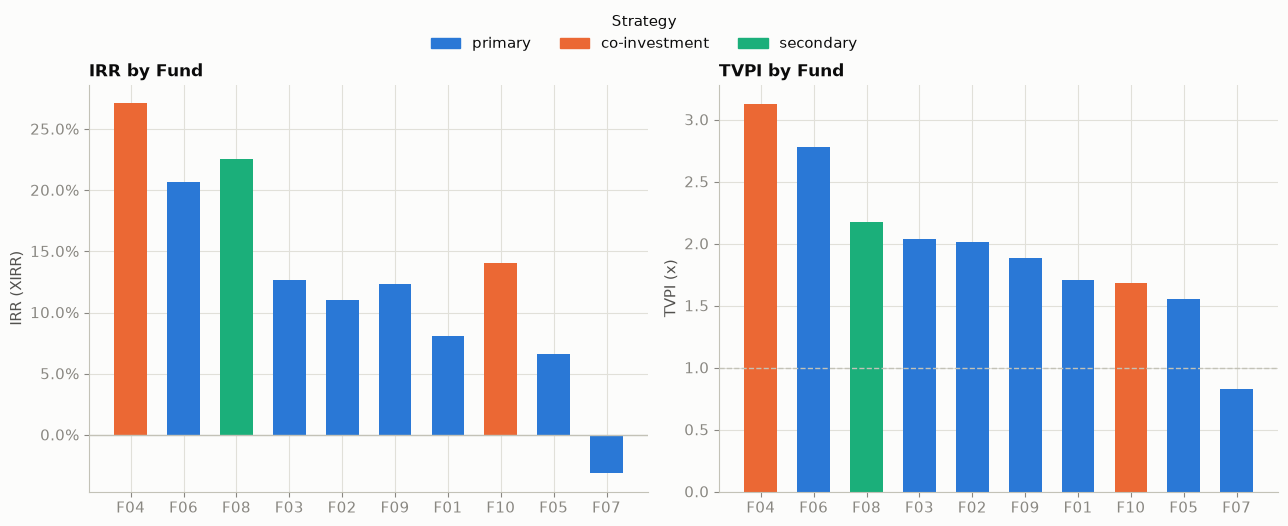

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_df = metrics_df.sort_values("TVPI", ascending=False)
colors = [STRATEGY_COLOR[s] for s in plot_df["Strategy"]]

ax = axes[0]
irr_vals = plot_df["IRR"].fillna(0.0)
ax.bar(plot_df["Fund ID"], irr_vals, color=colors, width=0.62)
ax.axhline(0, color=BASELINE, linewidth=1.0)
ax.set_title("IRR by Fund", loc="left", fontsize=12, fontweight="bold")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
ax.set_ylabel("IRR (XIRR)")

ax = axes[1]
ax.bar(plot_df["Fund ID"], plot_df["TVPI"], color=colors, width=0.62)
ax.axhline(1.0, color=BASELINE, linewidth=1.0, linestyle="--")
ax.set_title("TVPI by Fund", loc="left", fontsize=12, fontweight="bold")
ax.set_ylabel("TVPI (x)")

handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in STRATEGY_COLOR.values()]
fig.legend(handles, STRATEGY_COLOR.keys(), loc="upper center", bbox_to_anchor=(0.5, 1.06),
           ncol=3, frameon=False, title="Strategy")
fig.suptitle("")
plt.tight_layout()
plt.show()

**Reading this chart as an IC member would:** funds are sorted by TVPI, but notice IRR doesn't sort the same way — a fund with a strong TVPI but a lower IRR is typically a younger vintage where value has been created but not yet realized (high RVPI, low DPI), while a fund with a modest TVPI but a *good* IRR got there quickly. Co-investments (orange) show the widest dispersion, consistent with their concentrated, single-deal risk profile — exactly why they're sized as a satellite allocation, not the core of the program.

## 3. Public Market Equivalent (PME) Benchmarking

IRR and TVPI answer "how did the fund do." They don't answer the question an allocator actually cares about: **"was locking up capital in an illiquid, hard-to-exit buyout fund worth it, versus just buying a small-cap index instead?"** That's what PME is for.

Since this is a **small-cap buyout** portfolio, the natural public-market benchmark is the **Russell 2000**. We use a seeded, reproducible synthetic Russell-2000-like total return series (`pme_benchmarking.generate_synthetic_index`) rather than fetching real historical data, to keep the project fully self-contained — see the README for why.

- **Kaplan-Schoar PME (KS-PME):** future-value every cash flow to the valuation date using the index's return, then take `(FV of distributions + residual value) / FV of contributions`. **KS-PME > 1.0** means the fund beat what the same dollars would have earned in the index, dollar-weighted. This is the PME statistic most commonly quoted industry-wide.
- **Long-Nickels PME (LN-PME):** build a hypothetical shadow portfolio that receives the fund's *exact* calls and distributions but is invested in the index instead, then take the IRR of that shadow portfolio. The **spread** (fund IRR minus LN-PME IRR) is a clean, IRR-denominated measure of outperformance. Its known limitation: if a fund dramatically outperforms, the shadow portfolio's NAV can go negative (there isn't enough hypothetical index value left to fund later distributions) — when that happens the LN-PME IRR isn't economically meaningful, and this notebook flags it as such (`n/m`) rather than reporting a misleading number.

In [5]:
index = generate_synthetic_index(date(2012, 1, 1), AS_OF_DATE)
idx_total_return = index.levels.iloc[-1] / index.levels.iloc[0] - 1
print(f"Synthetic Russell 2000-like index: {idx_total_return:.0%} total return, {date(2012,1,1)} to {AS_OF_DATE}")

pme_rows = []
for f in funds:
    m = fund_metrics(f, as_of)
    r = pme_analysis(f, as_of, index, m.irr)
    pme_rows.append({
        "Fund ID": f.fund_id, "Strategy": f.strategy,
        "Fund IRR": r.fund_irr, "KS-PME": r.ks_pme, "LN-PME IRR": r.ln_pme_irr,
        "IRR Spread (bps)": r.irr_spread_bps,
    })
pme_df = pd.DataFrame(pme_rows)

portfolio_ks_pme = portfolio_kaplan_schoar_pme(funds, as_of, index)
print(f"\nPortfolio-wide KS-PME (pooled cash flows): {portfolio_ks_pme:.2f}x")

disp = pme_df.copy()
disp["Fund IRR"] = disp["Fund IRR"].map(lambda v: f"{v:.1%}" if v is not None else "n/m")
disp["KS-PME"] = disp["KS-PME"].map(lambda v: f"{v:.2f}x" if v is not None else "n/m")
disp["LN-PME IRR"] = disp["LN-PME IRR"].map(lambda v: f"{v:.1%}" if v is not None else "n/m")
disp["IRR Spread (bps)"] = disp["IRR Spread (bps)"].map(lambda v: f"{v:+.0f}" if v is not None else "n/m")
disp

Synthetic Russell 2000-like index: 225% total return, 2012-01-01 to 2026-06-30

Portfolio-wide KS-PME (pooled cash flows): 1.01x


,Fund ID,Strategy,Fund IRR,KS-PME,LN-PME IRR,IRR Spread (bps)
0,F01,primary,8.1%,0.93x,9.2%,-109
1,F02,primary,11.1%,0.93x,11.9%,-88
2,F03,primary,12.7%,0.86x,14.6%,-191
3,F04,co-investment,27.1%,1.63x,nan%,+nan
4,F05,primary,6.6%,0.63x,12.8%,-614
5,F06,primary,20.7%,1.20x,nan%,+nan
6,F07,primary,-3.1%,0.44x,9.7%,-1282
7,F08,secondary,22.6%,1.74x,7.8%,+1475
8,F09,primary,12.3%,1.22x,8.7%,+362
9,F10,co-investment,14.1%,1.32x,nan%,+nan


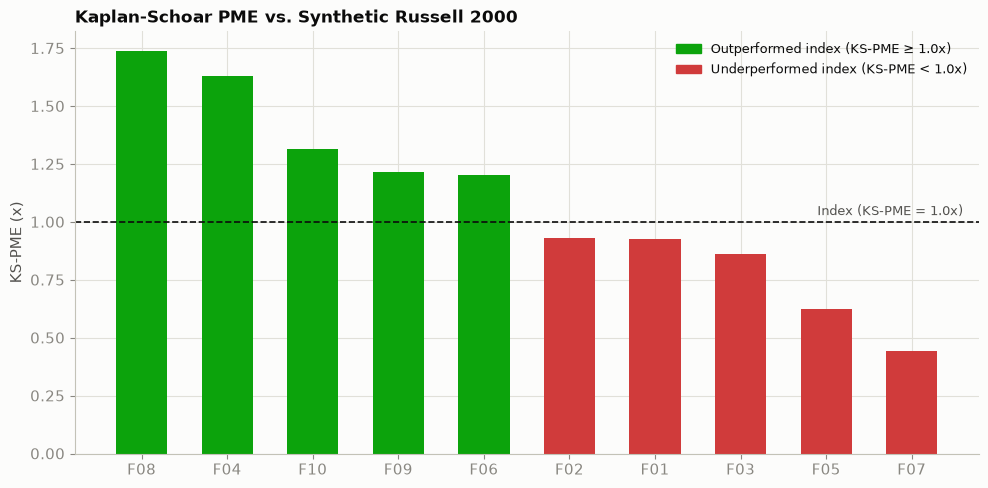

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
plot_df = pme_df.dropna(subset=["KS-PME"]).sort_values("KS-PME", ascending=False)
bar_colors = [STATUS_GOOD if v >= 1.0 else STATUS_CRITICAL for v in plot_df["KS-PME"]]
ax.bar(plot_df["Fund ID"], plot_df["KS-PME"], color=bar_colors, width=0.6)
ax.axhline(1.0, color=INK, linewidth=1.2, linestyle="--")
ax.text(len(plot_df) - 0.4, 1.03, "Index (KS-PME = 1.0x)", fontsize=9, color=INK_SECONDARY, ha="right")
ax.set_title("Kaplan-Schoar PME vs. Synthetic Russell 2000", loc="left", fontsize=12, fontweight="bold")
ax.set_ylabel("KS-PME (x)")

handles = [plt.Rectangle((0, 0), 1, 1, color=STATUS_GOOD), plt.Rectangle((0, 0), 1, 1, color=STATUS_CRITICAL)]
ax.legend(handles, ["Outperformed index (KS-PME ≥ 1.0x)", "Underperformed index (KS-PME < 1.0x)"],
          loc="upper right", frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

**Portfolio-level takeaway:** at a pooled KS-PME below 1.0x, this portfolio roughly tracked — and on this particular synthetic path, modestly lagged — a small-cap index that happened to post an unusually strong run. That's a legitimate, common outcome for a diversified buyout program benchmarked against a raging public-market bull run, and it's exactly why an IC shouldn't stop at PME: a FoF also underwrites **lower volatility, a smoother realization profile, and access to a return stream that isn't simply public-market beta** — value that a multiple-based PME doesn't fully capture. The fund-level dispersion above the line (co-investments and a few standout primaries) versus below it (the secondary and a couple of laggard primaries) is the more actionable read: it tells you *which* relationships to lean into for the next commitment cycle.

## 4. The J-Curve

Every PE fund draws capital down before it returns any — management fees and early acquisition costs create an immediate cash outflow, while portfolio companies take years to grow into their exit value. Plotted as **cumulative net cash flow** (distributions minus calls) against time since inception, this produces the fund's characteristic "J" shape.

This isn't just a chart for a pitch deck — it's the liquidity dynamic a fund-of-funds has to plan its entire commitment pace around (Section 5).

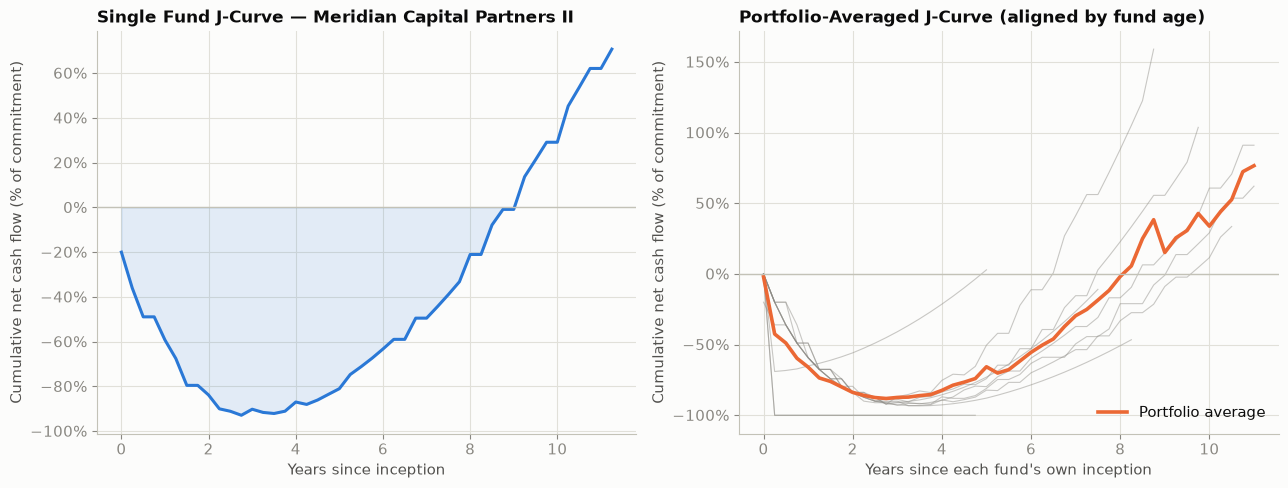

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

example_fund = next(f for f in funds if f.strategy == "primary" and f.is_realized)
curve = single_fund_jcurve(example_fund)
ax = axes[0]
ax.plot(curve["years_since_inception"], curve["cum_net_cf_pct_commitment"], color=BLUE, linewidth=2.2)
ax.axhline(0, color=BASELINE, linewidth=1.0)
ax.fill_between(curve["years_since_inception"], curve["cum_net_cf_pct_commitment"], 0,
                 where=(curve["cum_net_cf_pct_commitment"] < 0), color=BLUE, alpha=0.12)
ax.set_title(f"Single Fund J-Curve — {example_fund.name}", loc="left", fontsize=12, fontweight="bold")
ax.set_xlabel("Years since inception")
ax.set_ylabel("Cumulative net cash flow (% of commitment)")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))

avg_curve = portfolio_average_jcurve(funds)
ax = axes[1]
for fund_id in avg_curve.columns:
    if fund_id == "average":
        continue
    ax.plot(avg_curve.index, avg_curve[fund_id], color=INK_MUTED, linewidth=0.8, alpha=0.45)
ax.plot(avg_curve.index, avg_curve["average"], color=ORANGE, linewidth=2.6, label="Portfolio average")
ax.axhline(0, color=BASELINE, linewidth=1.0)
ax.set_title("Portfolio-Averaged J-Curve (aligned by fund age)", loc="left", fontsize=12, fontweight="bold")
ax.set_xlabel("Years since each fund's own inception")
ax.set_ylabel("Cumulative net cash flow (% of commitment)")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
ax.legend(frameon=False, loc="lower right")

plt.tight_layout()
plt.show()

The right-hand panel aligns every fund on **years since its own inception** (not calendar time) — the standard way industry vintage-year J-curve benchmarks are built — so funds from different vintages overlay on a common lifecycle axis. The thin gray lines are individual funds; the bold orange line is the equal-weighted average. The typical shape holds: a trough of roughly -80% to -90% of commitment by years 2-3, a crossover into positive net cash flow around years 8-9, consistent with the ~9-12 year fund lives in this portfolio.

## 5. Commitment Pacing Model

Manager selection answers "who." Pacing answers "when, and how much" — and it's a question a fund-of-funds has to answer *before* it knows how any given vintage will perform, because capital calls and distributions lag a commitment by years. Committing steadily, vintage after vintage, is how a FoF avoids both the risk of concentrating in a single (potentially weak) vintage year and the risk of being caught without cash on hand when calls come in unevenly.

We project a steady pace of **\$25M/year, split across 2-3 new fund commitments**, using a simplified model in the spirit of the Takahashi & Alexander (2001) cash flow pacing framework: capital calls are drawn down as a fraction of *remaining* uncalled commitment each year (naturally front-loaded, then tapering), and distributions ramp up over fund life against a growing NAV.

Total planned commitments (2026–2033): $200,000,000 across 24 funds
Peak aggregate NAV: $187,920,561 (around 2035-12-31)
Quarters with cumulative net cash flow still negative: 11.8 years from program start


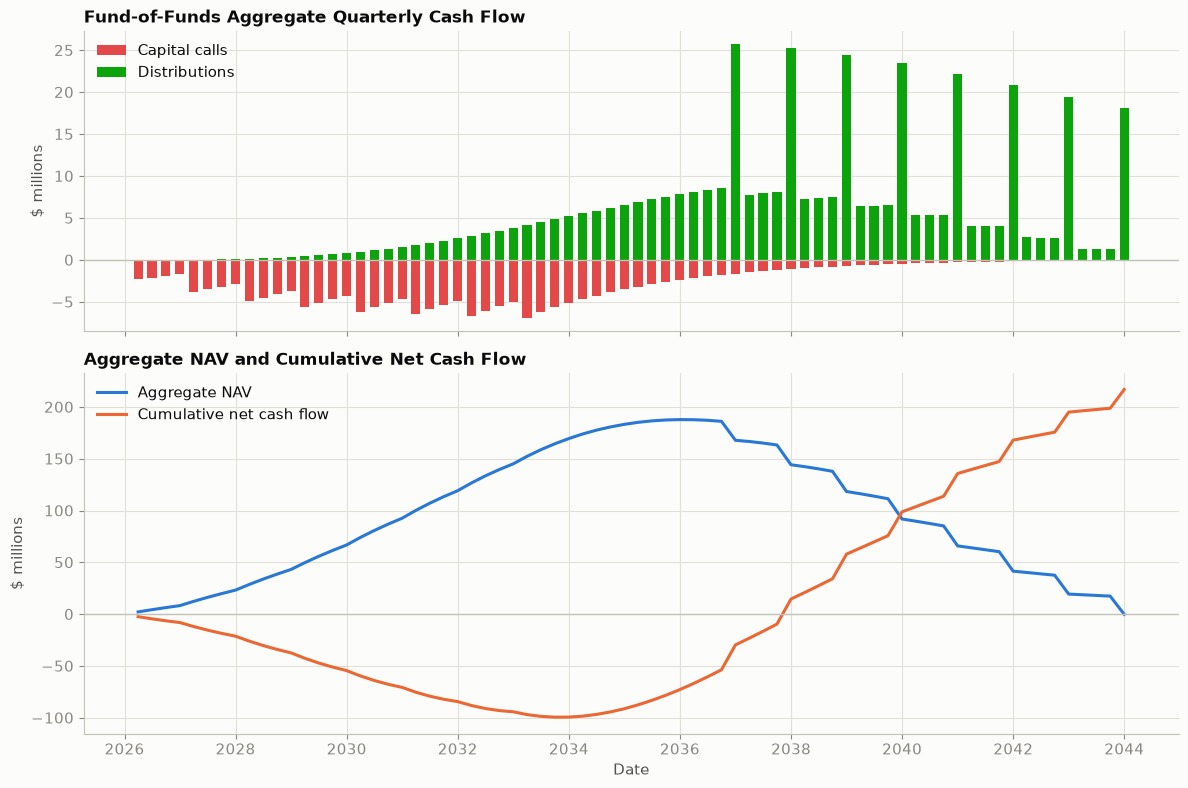

In [8]:
assumptions = PacingAssumptions(
    fund_life_years=11.0, contribution_rate_annual=0.32,
    distribution_rate_annual=0.28, growth_rate_annual=0.13,
)
aggregate, cohorts = project_commitment_pacing(
    start_year=2026, n_commitment_years=8, annual_commitment_target=25_000_000,
    commitments_per_year=3, assumptions=assumptions,
)

total_committed = cohorts.drop_duplicates("cohort_id")["commitment"].sum()
peak_nav = aggregate["nav"].max()
peak_nav_date = aggregate.loc[aggregate["nav"].idxmax(), "date"]
years_underwater = (aggregate["cumulative_net_cash_flow"] < 0).sum() / 4
print(f"Total planned commitments (2026–2033): ${total_committed:,.0f} across {cohorts['cohort_id'].nunique()} funds")
print(f"Peak aggregate NAV: ${peak_nav:,.0f} (around {peak_nav_date.date()})")
print(f"Quarters with cumulative net cash flow still negative: {years_underwater:.1f} years from program start")

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True, gridspec_kw={"height_ratios": [1, 1.2]})

ax = axes[0]
ax.bar(aggregate["date"], aggregate["contributions"] / 1e6, width=60, color=RED, label="Capital calls")
ax.bar(aggregate["date"], aggregate["distributions"] / 1e6, width=60, color=STATUS_GOOD, label="Distributions")
ax.axhline(0, color=BASELINE, linewidth=1.0)
ax.set_title("Fund-of-Funds Aggregate Quarterly Cash Flow", loc="left", fontsize=12, fontweight="bold")
ax.set_ylabel("$ millions")
ax.legend(frameon=False, loc="upper left")

ax = axes[1]
ax.plot(aggregate["date"], aggregate["nav"] / 1e6, color=BLUE, linewidth=2.2, label="Aggregate NAV")
ax.plot(aggregate["date"], aggregate["cumulative_net_cash_flow"] / 1e6, color=ORANGE, linewidth=2.2,
        label="Cumulative net cash flow")
ax.axhline(0, color=BASELINE, linewidth=1.0)
ax.set_title("Aggregate NAV and Cumulative Net Cash Flow", loc="left", fontsize=12, fontweight="bold")
ax.set_ylabel("$ millions")
ax.set_xlabel("Date")
ax.legend(frameon=False, loc="upper left")

plt.tight_layout()
plt.show()

**The liquidity-planning read:** even with a *steady, disciplined* \$25M/year pace, the program's cumulative net cash flow stays underwater for several years — the portfolio-level J-curve is the sum of every cohort's own J-curve, staggered by vintage. A fund-of-funds has to be capitalized (or have a credit facility) to fund calls through that stretch *before* earlier vintages start generating enough distributions to fund new commitments out of realizations rather than fresh capital. Aggregate NAV peaks mid-program and then declines as the earliest cohorts fully realize faster than new ones build — the standard shape of a maturing commitment program.

## 6. Manager Due-Diligence Scorecard

Quantitative metrics tell you what a manager's *funds* have returned. They say very little about whether that performance is repeatable — for that, a FoF analyst runs structured qualitative diligence alongside the numbers. This scorecard scores each GP relationship on four dimensions an IC memo would actually walk through, each on a 1-5 scale with an explicit, auditable rationale (not a black-box model):

1. **Team stability** — has the team that built the track record stayed together?
2. **Strategy consistency** — is the current fund investing the same way (sector, check size, geography) as the funds that generated the historical numbers?
3. **Track record dispersion vs. benchmark** — is outperformance broad-based across deals, or concentrated in one or two outliers?
4. **Fund size discipline** — is the new fund sized consistently with the opportunity set, or stepping up aggressively in a way that risks style drift?

In [9]:
profiles = generate_synthetic_manager_profiles(funds, benchmark_irr=0.09)
scorecard_rows = []
for f, p in zip(funds, profiles):
    r = score_manager(p)
    m = fund_metrics(f, as_of)
    scorecard_rows.append({
        "Fund ID": f.fund_id, "Manager": p.manager_name, "TVPI": m.tvpi,
        "Team": r.team_stability.score, "Strategy": r.strategy_consistency.score,
        "Dispersion": r.track_record_dispersion.score, "Fund Size": r.fund_size_discipline.score,
        "Overall": r.overall_score, "Rating": r.rating,
    })
scorecard_df = pd.DataFrame(scorecard_rows).sort_values("Overall", ascending=False).reset_index(drop=True)
scorecard_df

,Fund ID,Manager,TVPI,Team,Strategy,Dispersion,Fund Size,Overall,Rating
0,F06,Summit Ridge Capital,2.78,3.50,5.00,5.00,5.00,4.62,High Conviction — Recommend Commit
1,F04,Project Delta,3.13,3.50,3.50,5.00,3.50,3.95,Conviction — Commit
2,F08,Redwood Private Equity,2.17,5.00,3.50,2.00,3.50,3.43,Watch List — Commit with Reservations / Furthe...
3,F02,Cascade Buyout Fund,2.02,3.50,2.00,3.50,3.50,3.12,Watch List — Commit with Reservations / Furthe...
4,F09,Pinnacle Growth Partners,1.88,2.00,3.50,3.50,3.50,3.12,Watch List — Commit with Reservations / Furthe...
5,F10,Project Beacon,1.68,2.00,5.00,2.00,3.50,3.05,Watch List — Commit with Reservations / Furthe...
6,F03,Stonebridge Equity Partners,2.04,3.50,3.50,1.00,3.50,2.75,Watch List — Commit with Reservations / Furthe...
7,F05,Ironwood Partners,1.55,2.00,3.50,1.00,5.00,2.67,Watch List — Commit with Reservations / Furthe...
8,F07,Harborview Equity Partners,0.83,2.00,3.50,1.00,5.00,2.67,Watch List — Commit with Reservations / Furthe...
9,F01,Meridian Capital Partners,1.71,2.00,3.50,1.00,3.50,2.38,Decline


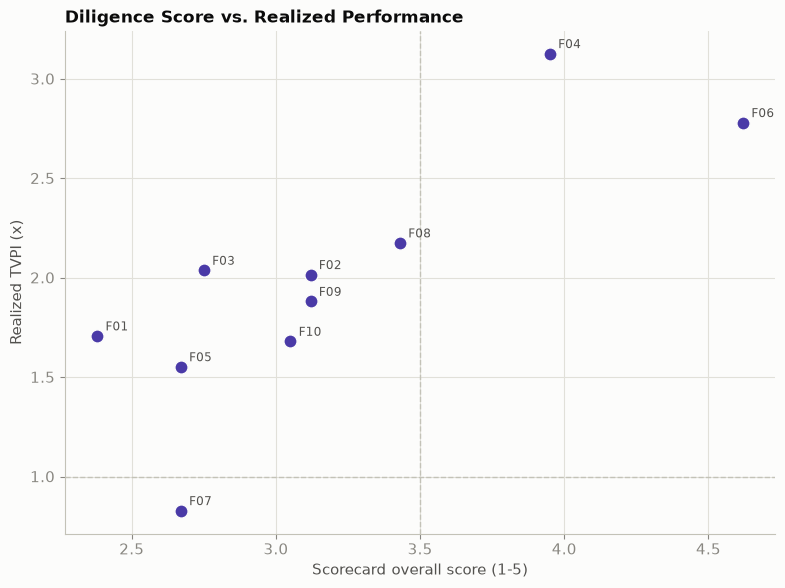

Correlation between scorecard score and realized TVPI: 0.80


In [10]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(scorecard_df["Overall"], scorecard_df["TVPI"], s=90, color=VIOLET, zorder=3, edgecolor=SURFACE, linewidth=1)
for _, row in scorecard_df.iterrows():
    ax.annotate(row["Fund ID"], (row["Overall"], row["TVPI"]), textcoords="offset points",
                xytext=(6, 4), fontsize=8.5, color=INK_SECONDARY)
ax.axvline(3.5, color=BASELINE, linewidth=1.0, linestyle="--")
ax.axhline(1.0, color=BASELINE, linewidth=1.0, linestyle="--")
ax.set_xlabel("Scorecard overall score (1-5)")
ax.set_ylabel("Realized TVPI (x)")
ax.set_title("Diligence Score vs. Realized Performance", loc="left", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

corr = np.corrcoef(scorecard_df["Overall"], scorecard_df["TVPI"])[0, 1]
print(f"Correlation between scorecard score and realized TVPI: {corr:.2f}")

The scorecard and realized performance are **positively correlated but far from perfectly aligned** — by design. Qualitative diligence is directional evidence that reduces risk, not a crystal ball: a manager can score well and still underperform (a strategy that was sound on paper can still hit a rough vintage), and a high scorecard doesn't guarantee a high TVPI. What the scorecard is actually for is **surfacing risk factors *before* the numbers exist** — for a fund still early in its J-curve, or for underwriting a first-time step-up fund, the qualitative framework is often the *only* evidence available at commitment time. Treating it as a repeatable, transparent process — not a single analyst's gut feel — is what makes it defensible in an IC memo.

## 7. Investment Committee Summary

**Portfolio construction:** 10 positions, \$97M paid-in across 2013-2020 vintages, blending 7 primary fund commitments with 2 co-investments and 1 secondary — a primary-led program with a modest opportunistic sleeve.

**Performance:** portfolio-wide **IRR of ~12.7%** and **TVPI of ~1.93x** (DPI 1.71x / RVPI 0.21x — the large majority of value already realized, not just marked). Dispersion across the ten positions is wide, as expected: co-investments show the highest highs and among the lower lows, consistent with their concentrated, single-deal risk.

**Benchmark-relative:** a pooled **KS-PME of ~0.9x** against a synthetic Russell 2000 that happened to post an unusually strong run over the period — a reminder that PME is one input, not a verdict, particularly when the public benchmark itself had an exceptional stretch.

**Liquidity:** a steady \$25M/year commitment pace stays cash-flow-negative for the first several years of the program even when every individual vintage is performing to plan — the portfolio-level J-curve compounds across staggered cohorts, which is the core planning constraint a fund-of-funds has to capitalize for.

**Manager quality:** the due-diligence scorecard flags real, auditable risk factors (team turnover, strategy drift, return concentration, fund-size step-ups) that correlate with — but don't simply restate — realized performance, which is exactly the kind of independent signal an IC wants going into a commitment decision, not after.